<a href="https://colab.research.google.com/github/ek182238/CSC349/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Dataset Loading and Dimensionality Inspection

Load the Olivetti Faces dataset using `sklearn.datasets.fetch_olivetti_faces`. Print the total number of samples, unique target subjects, feature dimensions, and plot a **4 x 5 grid** of sample faces labeled with their subject IDs.

Explanation: I split the dataset into X (everything except the target variable) and y (the target variable). I used X.shape[0] to print the number of samples (number of rows) and X.shape[1] to print the feature dimensions (number of columns). I also printed the amount of unique y values. I plotted a 4 x 5 grid of the first 20 faces and reshaped them to 64 x 64 so that they could be displayed without errors. I titled each face with their subject ID.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total number of samples: 400
Unique target subjects: 40
Feature dimensions: 4096


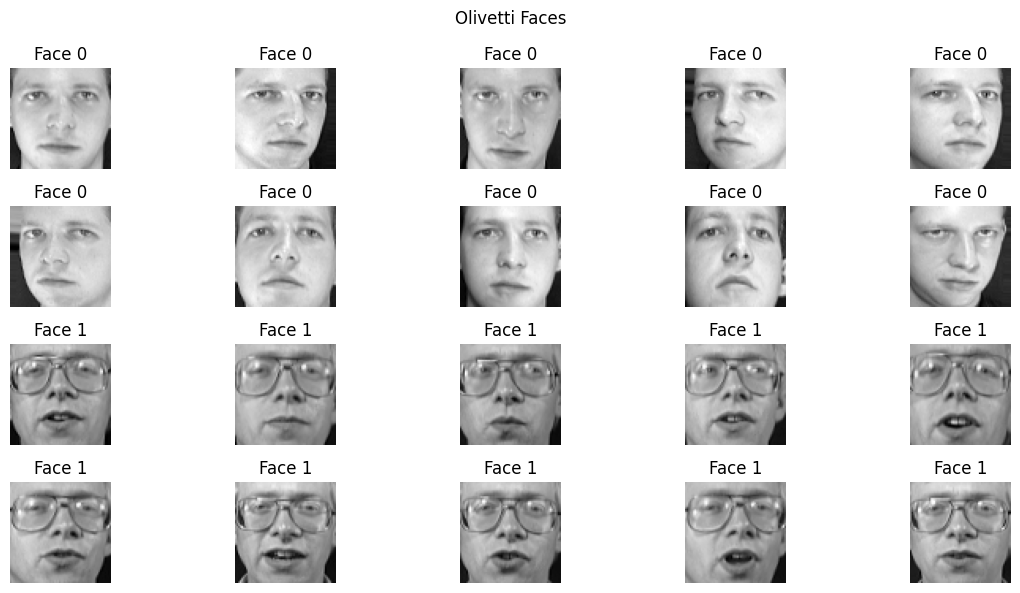

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces(random_state=42)

X = faces.data
y = faces.target

print(f"Total number of samples: {X.shape[0]}")
print(f"Unique target subjects: {len(np.unique(y))}")
print(f"Feature dimensions: {X.shape[1]}")

plt.figure(figsize=(12, 6))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X[i].reshape(64, 64), cmap='gray')
    plt.title(f"Face {y[i]}")
    plt.axis('off')

plt.suptitle("Olivetti Faces")
plt.tight_layout()
plt.show()

# Task 2: Cumulative Explained Variance & Elbow

Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.

Explanation: I initialized an fit the PCA, calculated the individual and cumulative explained variance ratios, and used np.argmax to calculate the number of components required to preserve 90%, 95%, and 99% of the cumulative variance. In the plot, I added dotted lines to represent the variance thresholds (x axis) and the number of components required for that threshold (y axis).

Number of principal components computed: 400
Number of components required to preserve 90%, 95%, & 99% variance respectively: 66, 123, 260


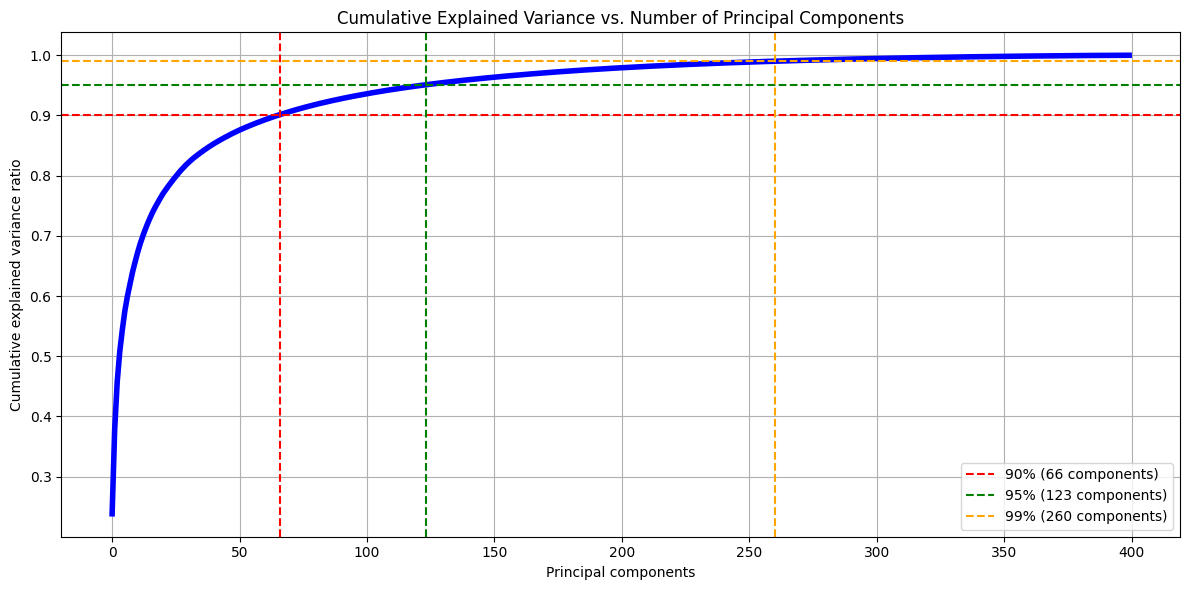

In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=None)
pca.fit(X)

individual_explained_variance = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(individual_explained_variance)

print(f'Number of principal components computed: {len(individual_explained_variance)}')

n_components_90 = np.argmax(cumulative_explained_variance >= 0.9) + 1
n_components_95 = np.argmax(cumulative_explained_variance >= 0.95) + 1
n_components_99 = np.argmax(cumulative_explained_variance >= 0.99) + 1
print(f'Number of components required to preserve 90%, 95%, & 99% variance respectively: {n_components_90}, {n_components_95}, {n_components_99}')

plt.figure(figsize=(12, 6))
plt.plot(cumulative_explained_variance, color='b', linewidth='4')
plt.xlabel('Principal components')
plt.ylabel('Cumulative explained variance ratio')
plt.title('Cumulative Explained Variance vs. Number of Principal Components')

plt.axhline(y=0.9, color='r', linestyle='--')
plt.axhline(y=0.95, color='g', linestyle='--')
plt.axhline(y=0.99, color='orange', linestyle='--')
plt.axvline(x=n_components_90, color='r', linestyle='--', label=f'90% ({n_components_90} components)')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'95% ({n_components_95} components)')
plt.axvline(x=n_components_99, color='orange', linestyle='--', label=f'99% ({n_components_99} components)')

plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

# Task 3: Image Compression and Reconstruction Analysis

Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. **Plot** a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the **Mean Squared Error (MSE)** between original and reconstructed faces as a function of k.

Explanation: I used plt.subplots with 5 rows and 6 columns (one for the original images and 5 for the reconstructions using different numbers of components). The first image in each row was the original, and then I looped through the list of component values to display the reconstructed faces reduced to each of the 5 values of components. I also plotted the MSE compared to the number of components, which showed that the MSE decreased in the reconstructions with more components.

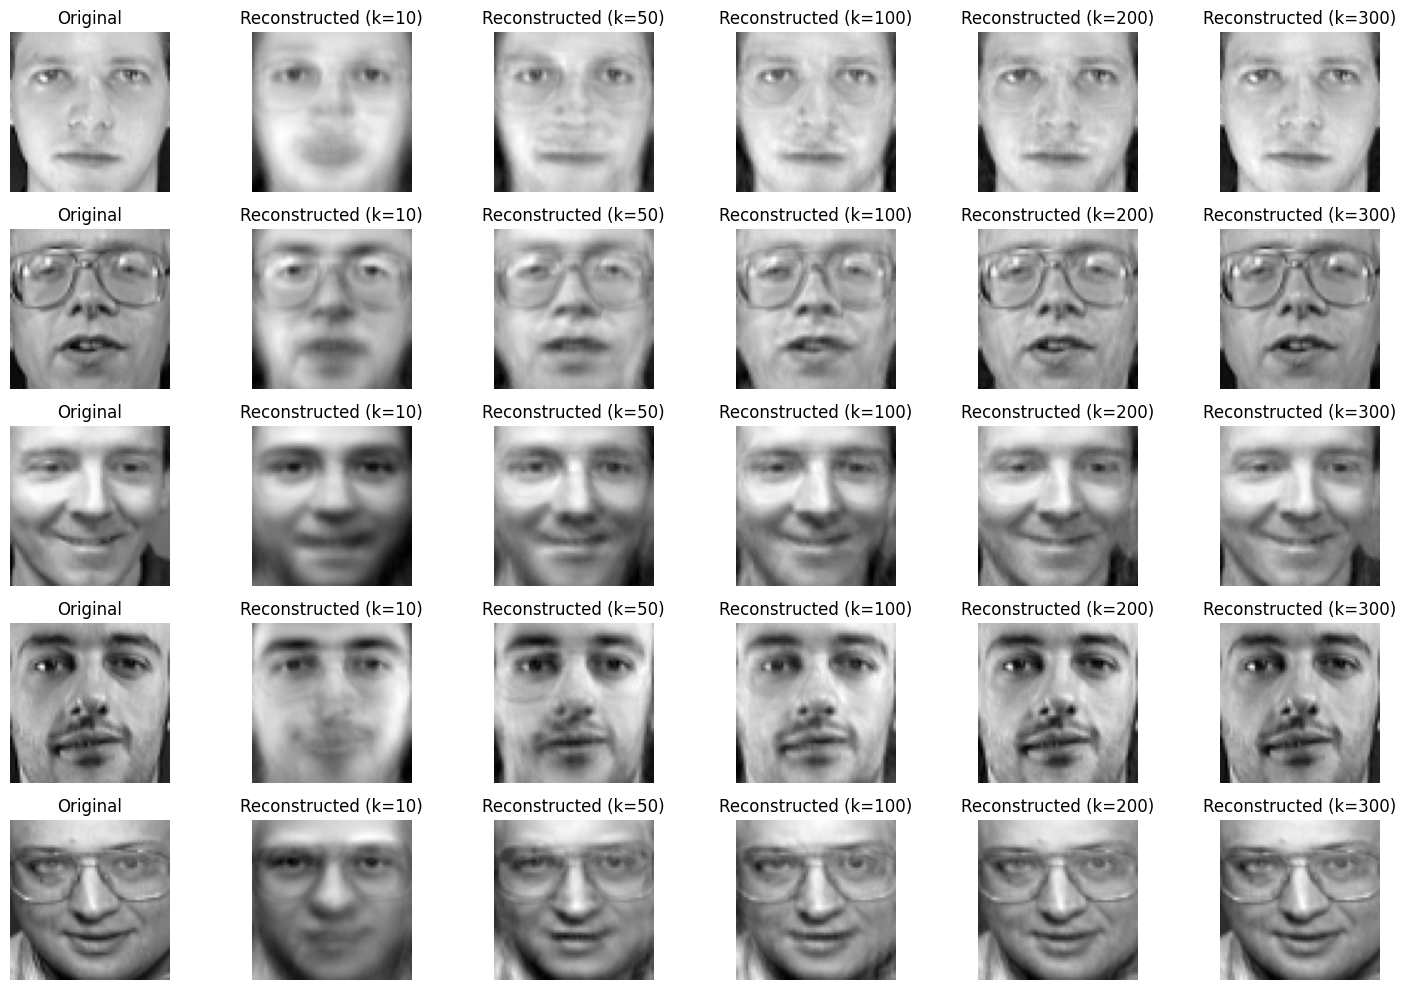

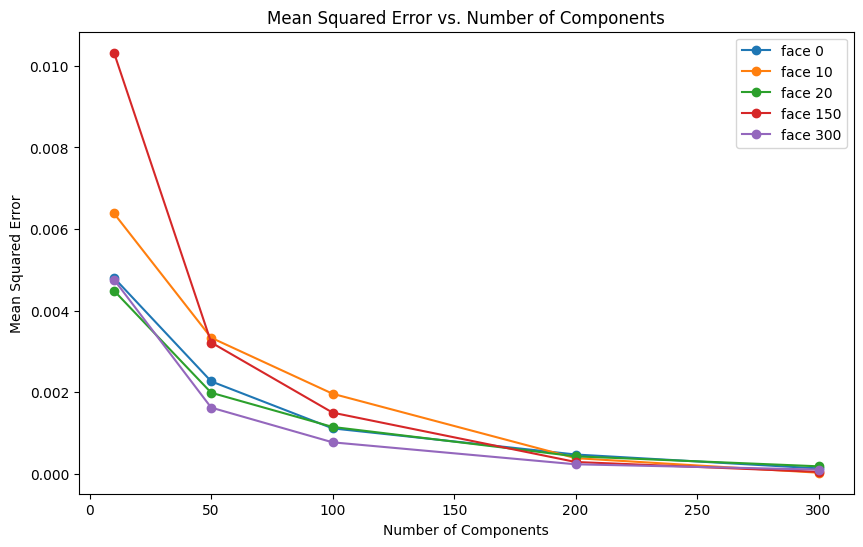

In [20]:
five_faces_indices = [0, 10, 20, 150, 300]
five_faces = X[five_faces_indices]
components = [10, 50, 100, 200, 300]
mse_array = []
fig, axes = plt.subplots(5, 6, figsize=(15, 10))

for i in range(5):
    actual_index = five_faces_indices[i]
    original_img = X[actual_index].reshape(64, 64)
    axes[i, 0].imshow(original_img, cmap='gray')
    axes[i, 0].set_title(f'Original')
    axes[i, 0].axis('off')

    for component_i, num_components in enumerate(components):
        pca_reduced = PCA(n_components=num_components)
        X_reduced = pca_reduced.fit_transform(X)
        X_reconstructed = pca_reduced.inverse_transform(X_reduced)
        reconstructed_img = X_reconstructed[actual_index].reshape(64, 64)

        mse = np.mean((original_img - reconstructed_img) ** 2)
        mse_array.append(mse)

        axes[i, component_i+1].imshow(reconstructed_img, cmap='gray')
        axes[i, component_i+1].set_title(f'Reconstructed (k={num_components})')
        axes[i, component_i+1].axis('off')

plt.tight_layout()
plt.show()

# MSE
mse_values = np.array(mse_array).reshape(5, 5)
plt.figure(figsize=(10, 6))
for i in range(5):
    plt.plot(components, mse_values[i], marker='o', linestyle='-', label=f'face {five_faces_indices[i]}')

plt.legend()
plt.xlabel('Number of Components')
plt.ylabel('Mean Squared Error')
plt.title('Mean Squared Error vs. Number of Components')
plt.show()

# Task 4: Visualization of "Eigenfaces"

Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a **3 x 5  plot grid ("Eigenfaces")**. **Annotate** each plot with the percentage of total variance explained by that specific component.

Explanation: I looped through the first 15 indices of the PCA components and reshaped them into 64 x 64 grids. I calculated the variance at each index. I set the title of each face to the index number and the variance of that particular face, and I removed the axis lines.

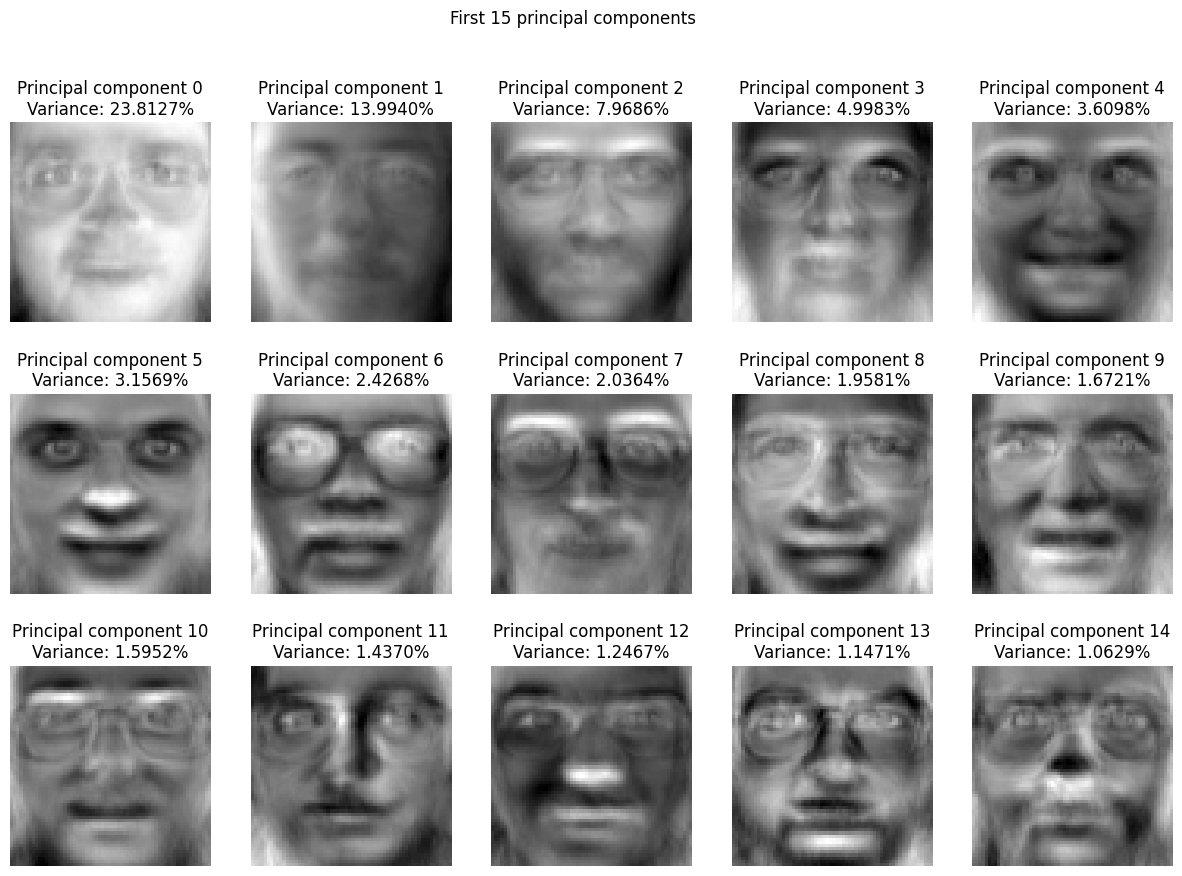

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(15, 10))

for i in range(3):
    for j in range(5):
        index = i * 5 + j
        eigenface = pca.components_[index].reshape(64, 64)
        variance = pca.explained_variance_ratio_[index] * 100

        axes[i, j].imshow(eigenface, cmap='gray')
        axes[i, j].set_title(f'Principal component {index}\nVariance: {variance:.4f}%')
        axes[i, j].axis('off')

plt.suptitle('First 15 principal components')
plt.show()

# Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)

Perform a stratified train/test split (80/20). Train a `LogisticRegression` classifier on:

1. The raw 4,096-dimensional feature vectors.

2. The PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set

Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).

Explanation: For the raw feature vectors, I made a LogisticRegression classifier and fitted the X_train and y_train data to it. For the PCA-reduced feature vectors, I first made a PCA (n_components=0.95 means that it uses the amount of components that explain 95% of variance). I fitted only the X_train data to it to prevent data leakage. I made the plot the same way that I made the plot in task 8.

Raw 4096-dimensional feature vectors:
Accuracy: 0.9625
Training time: 13.4505 seconds

PCA-reduced feature vectors using 95% variance threshold:
Accuracy: 0.9625
Training time: 0.5242 seconds


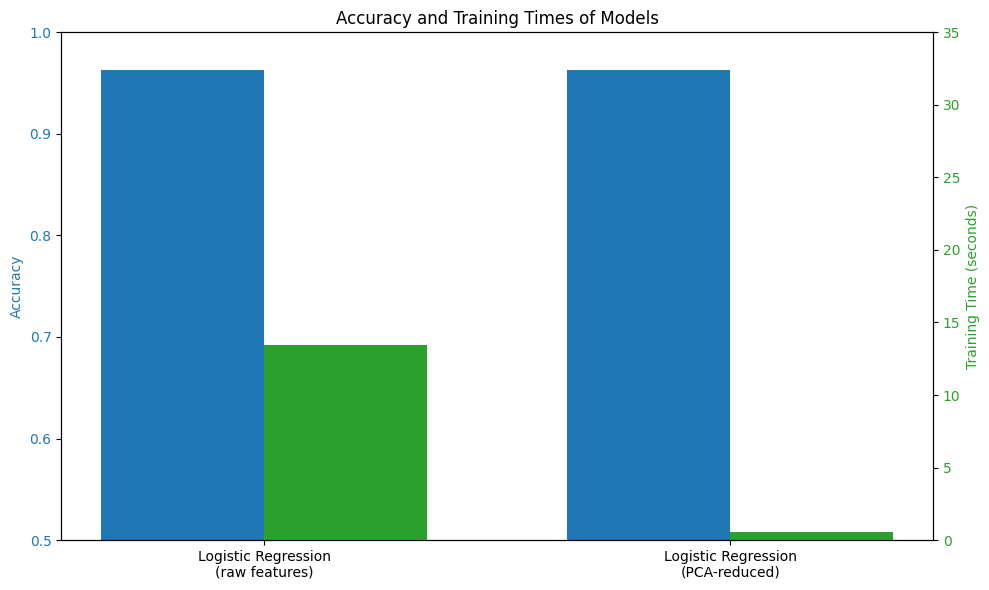

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

start_time = time.time()
lr_clf_raw = LogisticRegression(max_iter=1000, random_state=42)
lr_clf_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

y_pred_raw = lr_clf_raw.predict(X_test)
accuracy_raw = accuracy_score(y_test, y_pred_raw)

print('Raw 4096-dimensional feature vectors:')
print(f'Accuracy: {accuracy_raw:.4f}')
print(f'Training time: {raw_time:.4f} seconds')

start_time = time.time()
pca_reduced_clf = PCA(n_components=0.95)
X_train_reduced = pca_reduced_clf.fit_transform(X_train)
X_test_reduced = pca_reduced_clf.transform(X_test)

lr_clf_pca = LogisticRegression(max_iter=1000, random_state=42)
lr_clf_pca.fit(X_train_reduced, y_train)
pca_reduced_time = time.time() - start_time

y_pred_pca = lr_clf_pca.predict(X_test_reduced)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print('\nPCA-reduced feature vectors using 95% variance threshold:')
print(f'Accuracy: {accuracy_pca:.4f}')
print(f'Training time: {pca_reduced_time:.4f} seconds')

accuracies = [accuracy_raw, accuracy_pca]
times = [raw_time, pca_reduced_time]

# plot
models = ['Logistic Regression\n(raw features)',
          'Logistic Regression\n(PCA-reduced)']

accuracies = [accuracy_raw, accuracy_pca]
times = [raw_time, pca_reduced_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Accuracy bars
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color)
ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.5, 1)

# Training bars
ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Training Time (seconds)', color=color)
ax2.bar(x + width/2, times, width, label='Training Time', color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 35)

ax1.set_xticks(x)
ax1.set_xticklabels(models)

plt.title('Accuracy and Training Times of Models')
fig.tight_layout()
plt.show()

# Task 6: Non-Linear Classification (Kernel SVM)

Train a `SVC` with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.

Explanation: I trained a SVC with an RBF kernel and fitted it using the PCA-reducdd training features. I printed the accuracy score and training time. I displayed a confusion matrix that was 40 x 40 because there were 40 target subjects. Most of the predictions fall match with their true label.

Accuracy: 0.9375
Training time: 0.0301 seconds


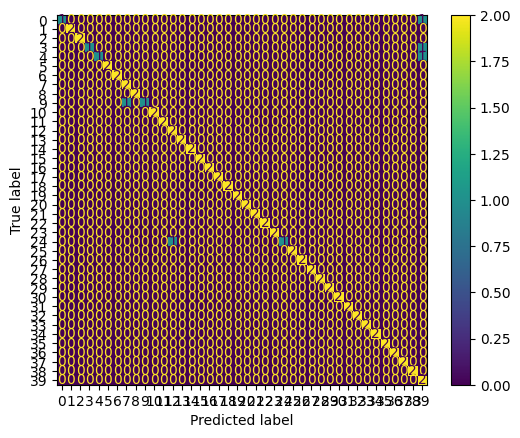

              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      0.50      0.67         2
           4       1.00      0.50      0.67         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       0.67      1.00      0.80         2
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       0.67      1.00      0.80         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
          17       1.00    

In [6]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

start_time = time.time()
svm_clf = SVC(kernel='rbf', random_state=42)
svm_clf.fit(X_train_reduced, y_train)
svm_time = time.time() - start_time

y_pred_svm = svm_clf.predict(X_test_reduced)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print(f'Accuracy: {accuracy_svm:.4f}')
print(f'Training time: {svm_time:.4f} seconds')

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm)
plt.show()
print(classification_report(y_test, y_pred_svm))

# Task 7: Ensemble Classification on PCA Features

Construct a `VotingClassifier` (soft voting) combining a **Polynomial Kernel SVM** (`degree=2`), an **RBF Kernel SVM**, and a `RandomForestClassifier` (`n_estimators=100`). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.

Explanation: I made the 3 classifiers and constructed a soft voting classifier using the polynomial SVM, RBF SVM, and random forest classifiers. I fitted the model with the PCA-reduced training data. I compared the accuracy score and training time of this model to the other models by making a small DataFrame so that it would be easy to print.

In [19]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

start_time = time.time()
poly_svm_clf = SVC(kernel='poly', degree=2, probability=True, random_state=42)
rbf_svm_clf = SVC(kernel='rbf', probability=True, random_state=42)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

ensemble_clf = VotingClassifier(
    estimators=[('poly_svm', poly_svm_clf), ('rbf_svm', rbf_svm_clf), ('random_forest', rf_clf)],
    voting='soft'
)

ensemble_clf.fit(X_train_reduced, y_train)
ensemble_time = time.time() - start_time

y_pred_ensemble = ensemble_clf.predict(X_test_reduced)
accuracy_ensemble = accuracy_score(y_test, y_pred_ensemble)

print(f'Accuracy: {accuracy_ensemble:.4f}')
print(f'Training time: {ensemble_time:.4f} seconds')

print('\nComparison against the single linear and non-linear models:')
comparison = pd.DataFrame({
    'Model': ['Logistic Regression (Raw Features)', 'Logistic Regression (PCA-Reduced)', 'SVC with RBF Kernel (PCA-Reduced)', 'Soft Voting (PCA-Reduced)'],
    'Accuracy': [accuracy_raw, accuracy_pca, accuracy_svm, accuracy_ensemble],
    'Training Time': [raw_time, pca_reduced_time, svm_time, ensemble_time]
})
print(comparison)

Accuracy: 0.9500
Training time: 0.9669 seconds

Comparison against the single linear and non-linear models:
                                Model  Accuracy  Training Time
0  Logistic Regression (Raw Features)    0.9625      13.450546
1   Logistic Regression (PCA-Reduced)    0.9625       0.524219
2   SVC with RBF Kernel (PCA-Reduced)    0.9375       0.030146
3           Soft Voting (PCA-Reduced)    0.9500       0.966916


# Task 8: Comprehensive Comparative Evaluation

Create a single summary bar plot comparing **Accuracy** (primary y-axis) and **Training Time in seconds** (secondary y-axis) across all four model configurations:

1. Logistic Regression (Raw Features)

2. Logistic Regression (PCA-Reduced)

3. Support Vector Classifier with RBF Kernel (PCA-Reduced)

4. Soft Voting Ensemble (PCA-Reduced)

Explanation: I plotted the accuracy bars first. Since they are all in the 0.90s range and very close in value, I set the y axis values from 0.5 to 1.0 instead of 0 to 1.0, to visualize the differences between the values. Then I plotted the training time bars using ax1.twinx() so that they share the same x axis, having different scales for y axis values. The graph shows that training logistic regression using raw features was significantly slower than the other models.

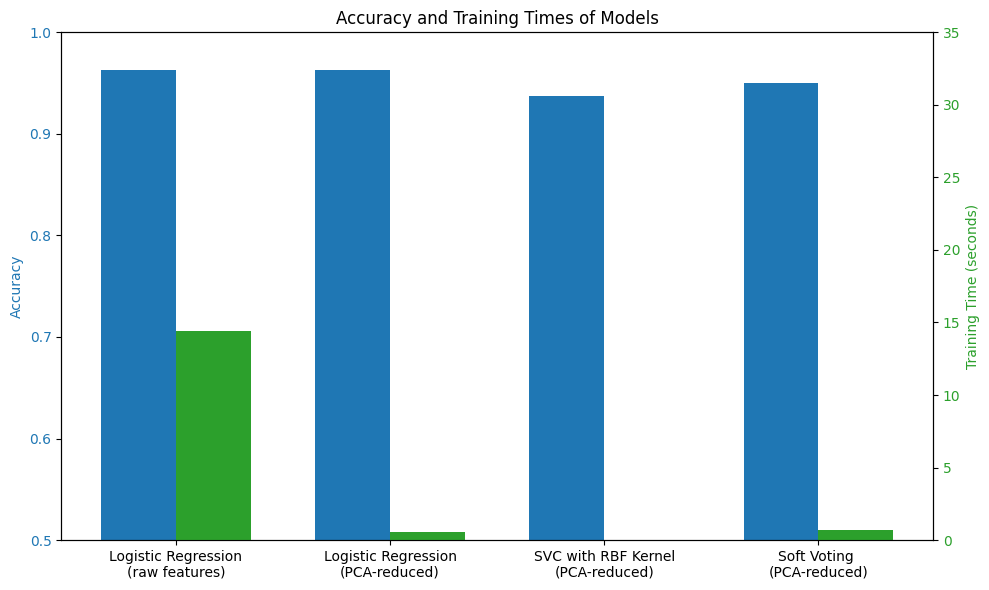

In [8]:
models = ['Logistic Regression\n(raw features)',
          'Logistic Regression\n(PCA-reduced)',
          'SVC with RBF Kernel\n(PCA-reduced)',
          'Soft Voting \n(PCA-reduced)']

accuracies = [accuracy_raw, accuracy_pca, accuracy_svm, accuracy_ensemble]
times = [raw_time, pca_reduced_time, svm_time, ensemble_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Accuracy bars
color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color)
ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.5, 1)

# Training bars
ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Training Time (seconds)', color=color)
ax2.bar(x + width/2, times, width, label='Training Time', color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 35)

ax1.set_xticks(x)
ax1.set_xticklabels(models)

plt.title('Accuracy and Training Times of Models')
fig.tight_layout()
plt.show()